In [1]:
import pandas as pd
import seaborn as sns
from ast import literal_eval
from datasets import load_dataset
import matplotlib.pyplot as plt


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].fillna('[]')
df['job_skills'] = df['job_skills'].apply(literal_eval)

c:\Users\Windows 11\miniconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df_US_DE = df[(df['job_title_short'] == 'Data Engineer') & (df['job_country'] == 'United States')].copy()

In [8]:
df_DE_US_EXP = df_US_DE.explode('job_skills')

In [7]:
df_US_DE['job_posted_month'] = df_US_DE['job_posted_date'].dt.month


In [22]:
df_pivot = df_DE_US_EXP.pivot_table(index='job_posted_month', columns='job_skills', aggfunc='size', fill_value=0)
df_pivot.loc['Total'] = df_pivot.sum()
df_pivot = df_pivot[df_pivot.loc['Total'].sort_values(ascending=False).index]
df_pivot = df_pivot.drop('Total')
df_pivot

job_skills,sql,python,aws,azure,spark,java,snowflake,hadoop,kafka,scala,...,lisp,fastify,qt,powerbi,mlpack,sqlserver,svelte,workfront,xamarin,wrike
job_posted_month,,,,,,,,,,,,,,,,,,,,,
1,1826,1745,1119,841,916,695,592,515,547,517,...,0,0,0,0,0,0,0,0,0,0
2,2109,2043,1415,965,1063,829,763,645,647,597,...,1,0,0,0,0,0,0,0,0,0
3,2204,2126,1472,1023,1038,791,704,640,605,587,...,0,0,0,0,0,0,0,0,0,0
4,1914,1868,1222,937,878,682,676,498,514,534,...,0,0,0,0,0,0,0,0,0,0
5,2077,2023,1252,990,952,730,681,529,491,509,...,0,0,0,0,0,0,0,0,1,0
6,2048,1882,1260,947,955,686,668,516,495,459,...,0,0,0,0,0,0,0,0,0,0
7,1789,1689,1166,794,821,615,624,483,448,461,...,1,0,1,0,0,0,0,1,0,0
8,2246,2155,1388,1003,1006,754,749,594,565,557,...,0,0,0,0,0,1,1,0,0,0
9,2090,1934,1267,960,941,671,700,479,500,483,...,0,0,0,1,0,0,0,0,0,0


In [24]:
df_totals = df_US_DE.groupby(by='job_posted_month').size()

In [ ]:
df_percent = df_pivot.div(df_totals/100, axis=0)

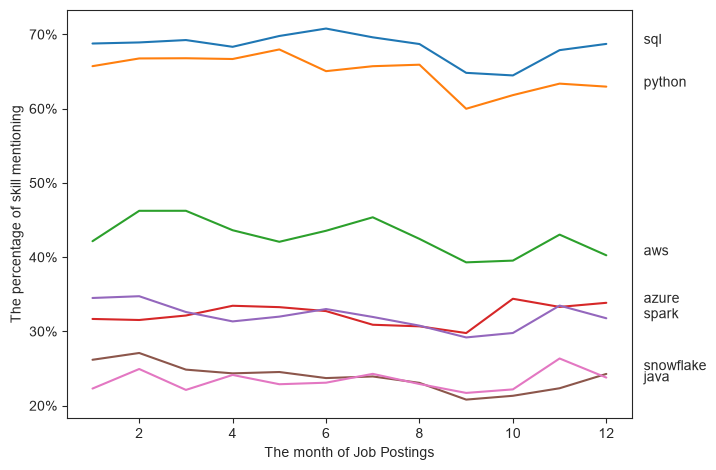

In [46]:
from matplotlib.ticker import PercentFormatter

df_plot = df_percent.iloc[:, :7]

sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.set_style('ticks')

plt.xlabel("The month of Job Postings")
plt.ylabel("The percentage of skill mentioning")

plt.tight_layout()
plt.legend().remove()


for i in range(7):
    y = df_plot.iloc[-1, i]
    skill = df_plot.columns[i]

    if skill == 'java':
        y -= 1
    elif skill == 'snowflake':
        y += 1

    plt.text(12.8, y, skill)

ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter())

plt.show()